In [ ]:
# ============================================
# 1. Import Libraries
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [ ]:
# ============================================
# 2. Load Dataset
# ============================================

train_df = pd.read_csv(r'C:\Users\gopin\OneDrive\Documents\Data_Science\Streamlit Training files\Comment Toxicity\train.csv')
test_df = pd.read_csv(r'C:\Users\gopin\OneDrive\Documents\Data_Science\Streamlit Training files\Comment Toxicity\test.csv')

In [ ]:

# ============================================
# 3. Train Dataset Overview
# ============================================

train_df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 9.7 MB


In [16]:
train_df['id'].nunique()

159571

In [9]:
train_df.describe(include='all')

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
count,159571,159571,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000,159571.000000
unique,159571,159571,NaN,NaN,NaN,NaN,NaN,NaN
top,0000997932d777bf,Explanation\nWhy the edits made under my usern...,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,0.095844,0.009996,0.052948,0.002996,0.049364,0.008805
std,NaN,NaN,0.294379,0.099477,0.223931,0.054650,0.216627,0.093420
min,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:

# ============================================
# 4. Test Dataset Overview
# ============================================

test_df.head()

,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
1,0000247867823ef7,== From RfC == \n\n The title is fine as it is...
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lap..."
3,00017563c3f7919a,":If you have a look back at the source, the in..."
4,00017695ad8997eb,I don't anonymously edit articles at all.


In [13]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153164 entries, 0 to 153163
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            153164 non-null  str  
 1   comment_text  153164 non-null  str  
dtypes: str(2)
memory usage: 2.3 MB


In [15]:
test_df['id'].nunique()

153164

In [17]:
test_df.describe(include='all')

,id,comment_text
count,153164,153164
unique,153164,153164
top,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
freq,1,1


In [ ]:
# ============================================
# 5. Missing Values
# ============================================

missing_values = train_df.isnull().sum()

print(missing_values)



id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


In [ ]:
# ============================================
# 6. Check for Duplicate Comments
# ============================================

duplicate_comments = train_df['comment_text'].duplicated().sum()

print("Duplicate Comments:", duplicate_comments)

Duplicate Comments: 0


In [ ]:
# ============================================
# 7. Check for Empty Comments
# ============================================

empty_comments = (
    train_df['comment_text']
    .str.strip()
    .eq('')
    .sum()
)

print("Empty Comments:", empty_comments)

Empty Comments: 0


In [ ]:
# ============================================
# 8. Analyze Label Distribution
# ============================================

labels = [
    'toxic',
    'severe_toxic',
    'obscene',
    'threat',
    'insult',
    'identity_hate'
]

label_counts = train_df[labels].sum()

print(label_counts)

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64


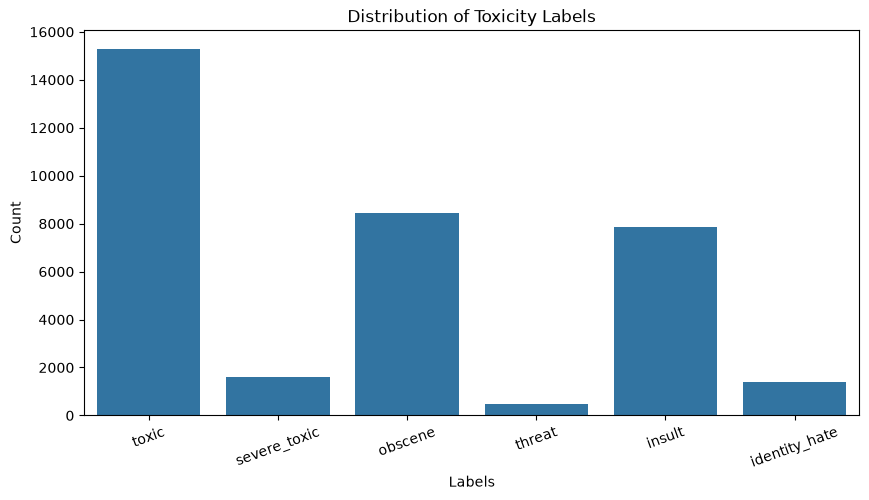

In [27]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Distribution of Toxicity Labels")
plt.xlabel("Labels")
plt.ylabel("Count")

plt.xticks(rotation=20)

plt.show()

In [ ]:
# ============================================
# 9. Identify Clean (Non-Toxic) Comments
# ============================================

train_df['clean'] = (train_df[labels].sum(axis=1) == 0)

train_df['clean'].value_counts()

clean
True     143346
False     16225
Name: count, dtype: int64

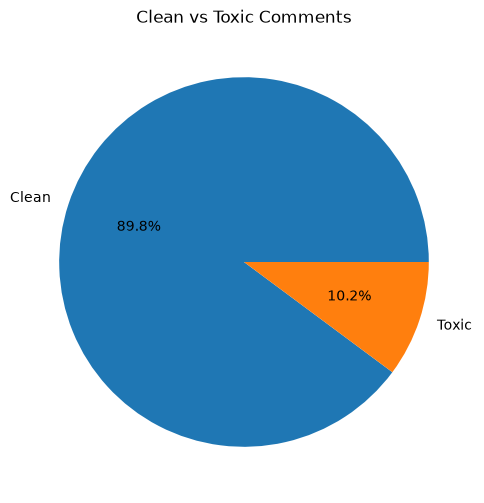

In [30]:
plt.figure(figsize=(6,6))

train_df['clean'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    labels=['Clean','Toxic']
)

plt.ylabel('')
plt.title("Clean vs Toxic Comments")

plt.show()

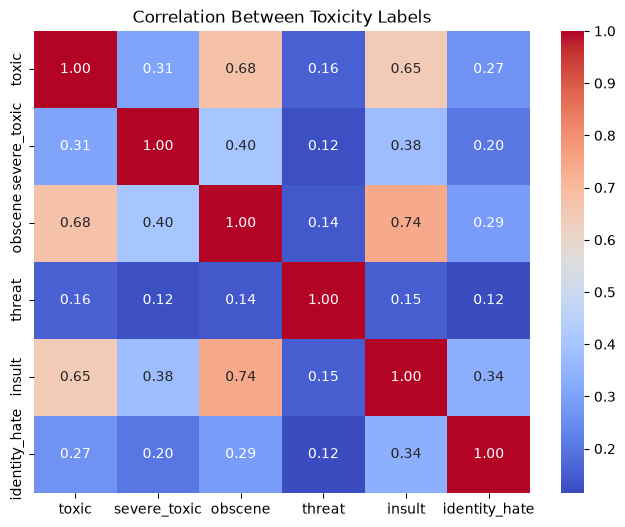

In [ ]:
# ============================================
# 10. Visualize Correlation Between Toxicity Labels
# ============================================

plt.figure(figsize=(8,6))

sns.heatmap(
    train_df[labels].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Toxicity Labels")
plt.show()

In [ ]:
# ============================================
# 11. Calculate Number of Labels per Comment
# ============================================

train_df['label_count'] = train_df[labels].sum(axis=1)

label_count = train_df['label_count'].value_counts().sort_index()

print(label_count)

label_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64


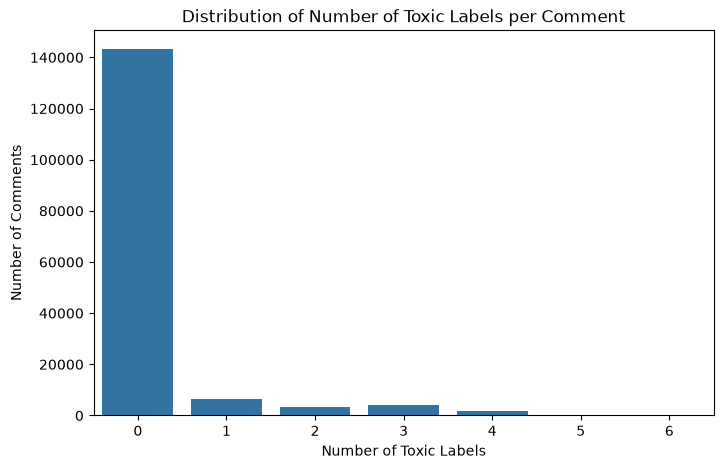

In [34]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='label_count',
    data=train_df
)

plt.title("Distribution of Number of Toxic Labels per Comment")
plt.xlabel("Number of Toxic Labels")
plt.ylabel("Number of Comments")

plt.show()

In [ ]:
# ============================================
# 12. Analyze Comment Length Distribution
# ============================================

train_df['comment_length'] = train_df['comment_text'].str.len()

train_df['comment_length'].describe()

count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: comment_length, dtype: float64

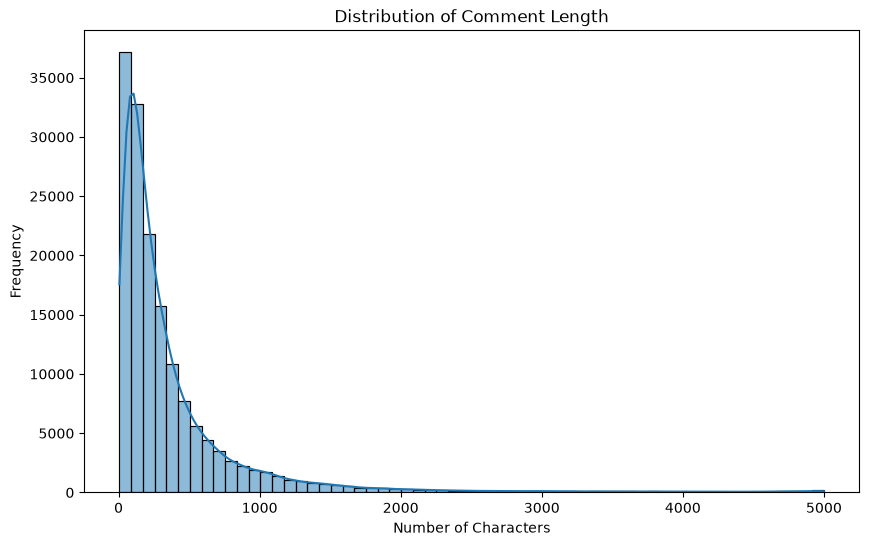

In [36]:
plt.figure(figsize=(10,6))

sns.histplot(
    train_df['comment_length'],
    bins=60,
    kde=True
)

plt.title("Distribution of Comment Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

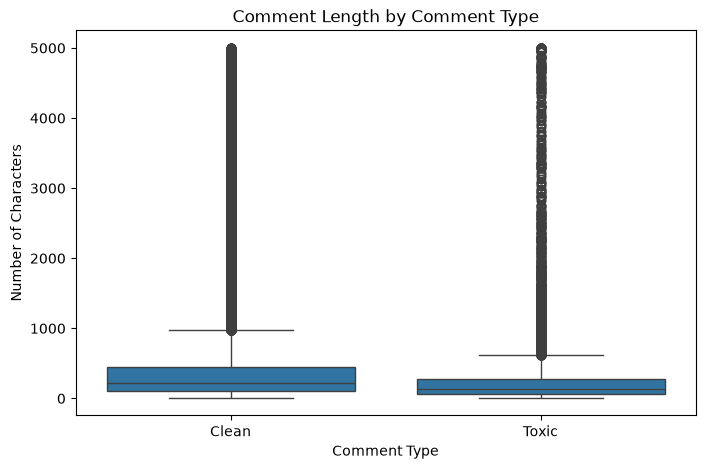

In [ ]:
# ============================================
# 13. Compare Comment Length by Comment Type
# ============================================

plot_df = train_df.copy()

plot_df['Comment Type'] = plot_df['clean'].map({
    True: 'Clean',
    False: 'Toxic'
})

plt.figure(figsize=(8,5))

sns.boxplot(
    data=plot_df,
    x='Comment Type',
    y='comment_length'
)

plt.title("Comment Length by Comment Type")
plt.xlabel("Comment Type")
plt.ylabel("Number of Characters")

plt.show()

In [ ]:
# ============================================
# 14. Text Cleaning Function for EDA
# ============================================

from collections import Counter
from wordcloud import WordCloud
import re

def clean_text_eda(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [42]:
clean_comments = train_df[train_df['clean'] == True]
toxic_comments = train_df[train_df['clean'] == False]

In [43]:
clean_text = clean_comments['comment_text'].apply(clean_text_eda)
toxic_text = toxic_comments['comment_text'].apply(clean_text_eda)

In [ ]:
# ============================================
# 15. Identify Most Frequent Words in Clean Comments
# ============================================

clean_words = " ".join(clean_text).split()

clean_counter = Counter(clean_words)

top_clean = clean_counter.most_common(20)

print('top clean words')

top_clean

top clean words


[('the', 472472),
 ('to', 279304),
 ('of', 211365),
 ('and', 204923),
 ('a', 192866),
 ('i', 179276),
 ('you', 167256),
 ('is', 162093),
 ('that', 145550),
 ('in', 136734),
 ('it', 121984),
 ('for', 97186),
 ('this', 91050),
 ('not', 87917),
 ('on', 84068),
 ('be', 79296),
 ('as', 73789),
 ('have', 67102),
 ('are', 63095),
 ('if', 55316)]

In [ ]:
# ============================================
# 16. Identify Most Frequent Words in Toxic Comments
# ============================================

toxic_words = " ".join(toxic_text).split()

toxic_counter = Counter(toxic_words)

top_toxic = toxic_counter.most_common(20)

top_toxic_df = pd.DataFrame(top_toxic, columns=['Word','Count'])

print('top toxic words')

top_toxic

top toxic words


[('you', 37300),
 ('the', 22957),
 ('a', 22060),
 ('i', 21374),
 ('to', 17537),
 ('and', 17427),
 ('is', 13853),
 ('of', 12638),
 ('your', 9642),
 ('are', 8778),
 ('that', 8733),
 ('fuck', 8677),
 ('it', 7648),
 ('in', 7433),
 ('my', 6584),
 ('this', 6027),
 ('me', 5789),
 ('not', 5415),
 ('on', 5374),
 ('for', 5254)]

In [ ]:

import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gopin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [ ]:
# ============================================
# 17. Remove Stopwords and Redefine Text Cleaning Function for EDA
# ============================================

import re

def clean_text_eda(text):
    text = text.lower()

    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [54]:
clean_text = clean_comments['comment_text'].apply(clean_text_eda)
toxic_text = toxic_comments['comment_text'].apply(clean_text_eda)

In [ ]:
# ============================================
# 18. Identify Top Clean Words After Stopword Removal
# ============================================

clean_words = " ".join(clean_text).split()

clean_counter = Counter(clean_words)

top_clean = clean_counter.most_common(20)

print('after stop word removal top clean words')
top_clean

after stop word removal top clean words


[('article', 53895),
 ('page', 43323),
 ('wikipedia', 32117),
 ('talk', 30125),
 ('please', 28588),
 ('would', 28060),
 ('one', 26419),
 ('like', 23935),
 ('dont', 22216),
 ('see', 20457),
 ('also', 19721),
 ('think', 18648),
 ('im', 17244),
 ('articles', 16967),
 ('know', 16646),
 ('edit', 16563),
 ('use', 15819),
 ('people', 15718),
 ('may', 15220),
 ('time', 14245)]

In [ ]:
# ============================================
# 19. Identify Top Toxic Words After Stopword Removal
# ============================================

toxic_words = " ".join(toxic_text).split()

toxic_counter = Counter(toxic_words)

top_toxic = toxic_counter.most_common(20)

top_toxic_df = pd.DataFrame(top_toxic, columns=['Word','Count'])

print('after stop word removal top toxic words')
top_toxic

after stop word removal top toxic words


[('fuck', 8677),
 ('dont', 3886),
 ('like', 3769),
 ('shit', 3657),
 ('wikipedia', 3485),
 ('nigger', 3295),
 ('fucking', 3241),
 ('suck', 3050),
 ('go', 2932),
 ('ass', 2660),
 ('u', 2648),
 ('hate', 2637),
 ('get', 2428),
 ('know', 2348),
 ('page', 2344),
 ('gay', 2251),
 ('im', 2230),
 ('die', 2136),
 ('people', 1985),
 ('fat', 1979)]

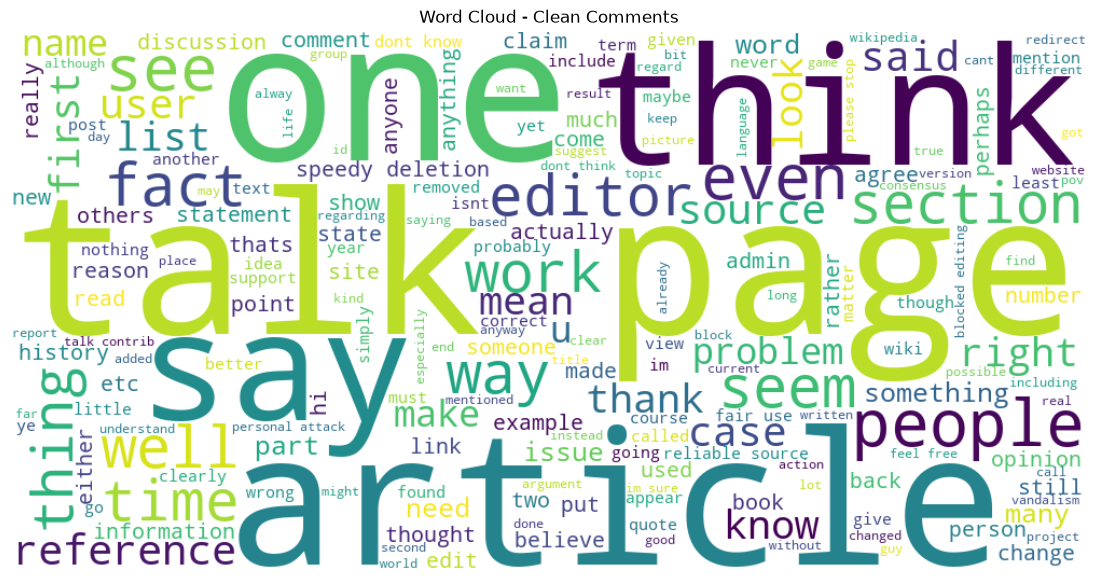

In [60]:
wordcloud_clean = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(" ".join(clean_text))

plt.figure(figsize=(15,7))
plt.imshow(wordcloud_clean, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud - Clean Comments")
plt.show()

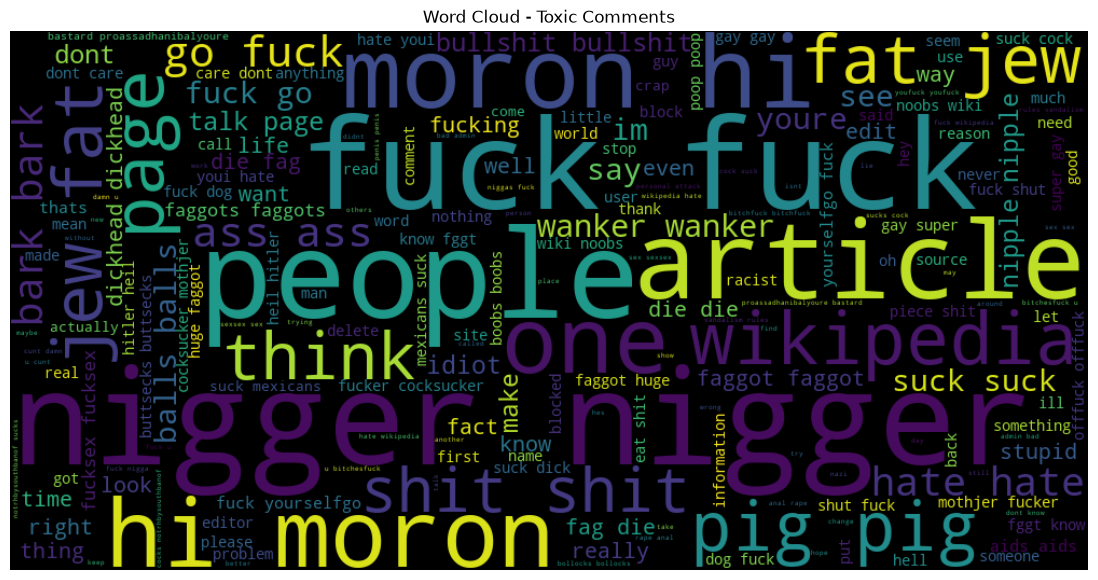

In [61]:
wordcloud_toxic = WordCloud(
    width=1000,
    height=500,
    background_color='black'
).generate(" ".join(toxic_text))

plt.figure(figsize=(15,7))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud - Toxic Comments")
plt.show()